In [ ]:
# Install required packages
!pip install -q torch_geometric
!pip install -q pynndescent
!pip install -q scanpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 15.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.1/169.1 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.2/58.2 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.1/254.1 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 95.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.7/53.7 kB 4.5 MB/s eta 0:00:00


In [ ]:
# Import modules
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import anndata as ad
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
import torch_geometric
from torch_geometric.nn import GATConv
import pynndescent
from scipy import sparse as sp
from tqdm import tqdm

In [ ]:
# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# AEs Initialization
In this notebook the two modality AutoEncoders are trained till stabilization to initialize them for the alignment phase.

# Load data

In [ ]:
# Load MERFISH AnnData
adata_st = sc.read_h5ad('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_spatial_train.h5ad')
adata_st

AnnData object with n_obs × n_vars = 10000 × 155
    obs: 'Cell_ID', 'Animal_ID', 'Animal_sex', 'Behavior', 'Bregma', 'Centroid_X', 'Centroid_Y', 'Cell_class', 'Neuron_cluster_ID', 'batch'
    var: 'mean', 'std'
    uns: 'Cell_class_colors', 'log1p'
    obsm: 'spatial', 'spatial3d'

In [ ]:
# Load sc data
adata_sc = sc.read_h5ad('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_scRNA_train.h5ad')
adata_sc

AnnData object with n_obs × n_vars = 28390 × 155
    obs: 'Sex', 'Replicate_number', 'Cell_class', 'Non-neuronal_cluster_ID', 'Neuronal_cluster_ID'
    var: 'mean', 'std'
    uns: 'log1p'

# Dataset and DataLoader

The spatial data encoder leverages a Graph Attention Network (GAT) to capture the underlying spatial relationships between spots. To efficiently construct the graph of spatial neighbors, pynndescent, a fast and scalable approximate nearest neighbor search algorithm is used.

Pynndescent builds a k-nearest neighbor graph by iteratively refining neighbor candidates, enabling efficient handling of high-dimensional spatial coordinates without exhaustive distance computations.

Custom knn building utilities for the spatial data and Dataset classes are built for both modalities.

Additionally, classes are designed to implement custom collate_fn arguments for the DataLoaders in order to manage batching for both modalities.


In [ ]:
def get_knn(location, n_neighbors):
    index = pynndescent.NNDescent(location, n_neighbors=n_neighbors)
    neighbor_idx, neighbor_dist = index.neighbor_graph
    return neighbor_idx, neighbor_dist

def knn_to_adj(knn_idx, knn_dist):

    n_samples, n_neighbors = knn_idx.shape

    row = np.repeat(np.arange(n_samples), n_neighbors)
    col = knn_idx.flatten()
    data = np.ones(n_samples * n_neighbors)

    adj_matrix = sp.csr_matrix((data, (row, col)), shape=(n_samples, n_samples))
    return adj_matrix

def location_to_edge(location, n_neighbors):
    idx, dist = get_knn(location, n_neighbors)
    adj = knn_to_adj(idx, dist)
    edge = torch_geometric.utils.from_scipy_sparse_matrix(adj)[0]
    return edge

In [ ]:
class spatialDataset(Dataset):

    def __init__(self, data_fit, location):
        data_fit = data_fit.toarray() if sp.issparse(data_fit) else data_fit
        assert len(data_fit) == len(location)
        self.data_fit = data_fit
        self.location = location

    def __len__(self):
        return len(self.data_fit)

    def __getitem__(self, index):
       return self.data_fit[index], self.location[index], index

class rnaDataset(Dataset):

    def __init__(self, data_fit):
        self.data_fit = data_fit.toarray() if sp.issparse(data_fit) else data_fit

    def __len__(self):
        return len(self.data_fit)

    def __getitem__(self, index):
        return self.data_fit[index], index


class rnaCollate():
    def __init__(self, device='cpu'):
        self.device = device

    def __call__(self, batch):
        batch_fit, batch_idx = zip(*batch)  # unzip the batch
        batch_fit = torch.from_numpy(np.vstack(batch_fit)).to(self.device)  # shape: [B, D]
        batch_idx = torch.tensor(batch_idx, dtype=torch.long).to(self.device)  # shape: [B]
        return batch_fit, batch_idx


class spatialCollate():

    def __init__(self, knn = 10, device='cpu'):
        self.device = device
        self.knn = knn

    def __call__(self, batch):
        batch_fit, batch_location, batch_idx = zip(*batch)

        batch_fit = torch.from_numpy(np.vstack(batch_fit)).to(self.device)
        batch_location = np.vstack(batch_location)
        batch_edge = location_to_edge(batch_location, self.knn).to(self.device)
        batch_idx = torch.tensor(batch_idx, dtype=torch.long).to(self.device)

        return batch_fit, batch_edge, batch_idx

# Model definition

## SC Autoencoder
The single cell AE is made of two MLP networks.
The encoder has been powered up with an additional layer, wrt to the stAI one, to better keep up with the spatial encoder.

Tuning can be done for:
* the number and size of hidden layers
* dropout probability
* weight initialization.

In [ ]:
class EncoderSC(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent, dropout=0.0):
        super().__init__()
        self.d_input = d_input
        self.d_latent = d_latent
        self.d_hidden = d_hidden
        self.model = nn.Sequential(nn.Linear(d_input, d_hidden),
                                   nn.ReLU(),
                                   nn.Dropout(dropout),
                                   nn.Linear(d_hidden, d_hidden),
                                   nn.ReLU(),
                                   nn.Linear(d_hidden, d_latent))
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0, std=0.1)
                torch.nn.init.normal_(module.bias, mean=0, std=0.1)

    def forward(self, x):
        z = self.model(x)
        return z


class DecoderSC(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent):
        super().__init__()
        self.d_input = d_input
        self.d_latent = d_latent
        self.d_hidden = d_hidden
        self.model = nn.Sequential(nn.Linear(d_latent, d_hidden),
                                   nn.ReLU(),
                                   nn.Linear(d_hidden, d_input))
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0, std=0.1)
                torch.nn.init.normal_(module.bias, mean=0, std=0.1)

    def forward(self, z):
        x = self.model(z)
        return x

## Spatial Autoencoder

The  spatial GAT-based autoencoder is a neural network architecture that combines graph attention mechanisms with an autoencoding framework to learn meaningful low-dimensional embeddings from graph-structured data. The encoder uses Graph Attention Network (GAT) layers to aggregate and weigh features from neighboring nodes based on learned attention scores, capturing complex local relationships.

The main tunable parameters are:
* the number of neighbours in the graph
* the number of attention heads
* the dropout coefficient (Bernoulli parameter)
* whether or not using the residual connection

Here we maintained the stAI parameters.

In [ ]:
class GATLayer(nn.Module):
    def __init__(self, d_input, num_heads=4, n_layers=1, dropout=0.0, residual=True):
        super().__init__()
        self.residual = residual
        self.num_heads = num_heads
        self.conv_layers = nn.ModuleList()
        self.n_layers = n_layers

        for i in range(self.n_layers):
            self.conv_layers.append(GATConv(d_input, d_input, heads=num_heads, concat=False))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index):
        if self.residual:
            resid = x
        for layer in self.conv_layers:
            x = layer(x, edge_index)
            x = self.dropout(F.leaky_relu(x))
        if self.residual:
            x += resid
        return x

class EncoderST(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent, num_heads=1, n_layers=1, dropout=0.0, residual=True):
        super().__init__()

        self.pre_fc = nn.Sequential(nn.Linear(d_input, d_hidden, bias=True),
                                    nn.ReLU(),
                                    nn.Dropout(dropout),
                                    nn.Linear(d_hidden, d_latent, bias=True))
        self.post_fc = nn.Linear(d_latent, d_latent, bias=True)
        self.gat_layer = GATLayer(d_input=d_latent, num_heads=num_heads, n_layers=n_layers, dropout=dropout, residual=residual)

    def forward(self, x, e):
        z = self.pre_fc(x)
        z = self.gat_layer(z, e)
        z = self.post_fc(z)

        return z


class DecoderST(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent):
        super().__init__()
        self.d_input = d_input
        self.d_latent = d_latent
        self.d_hidden = d_hidden
        self.model = nn.Sequential(nn.Linear(d_latent, d_hidden),
                                   nn.ReLU(),
                                   nn.Linear(d_hidden, d_input))
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0, std=0.1)
                torch.nn.init.normal_(module.bias, mean=0, std=0.1)

    def forward(self, z):
        x = self.model(z)
        return x

# Loss function

### Reconstruction Losses
For reconstruction the standard Pytorch MSELoss is used for both modalities.

### Consistency Loss
As in stAI, a consistency loss for cross modality coherence is used.

From the stAI paper: "*To keep the cells of the same type from the two datasets consistent in the latent space, [...], we apply another consistence loss, which
measures the cosine distance between the original data and
the data reconstructed from the coupling decoder*".

In [ ]:
class ConsistenceLoss(nn.Module):
    def __init__(self, decoder_sc, decoder_st):
        super().__init__()
        self.SC_decoder = decoder_sc
        self.ST_decoder = decoder_st

    def forward(self, SC_fit, ST_fit, SC_latent, ST_latent):
        loss = (1 - torch.sum(F.normalize(self.SC_decoder(ST_latent), p=2) * F.normalize(ST_fit, p=2), 1)).mean()+\
              (1 - torch.sum(F.normalize(self.ST_decoder(SC_latent), p=2) * F.normalize(SC_fit, p=2), 1)).mean()
        return loss

# Full Model

In [ ]:
class CrossModalAE(nn.Module):

    def __init__(self,
                d_input,
                d_hidden,
                d_latent,
                dropout=0.1,
                lambda_recon=1.0,
                lambda_consistence=1.0,
                batchsize_scrna=64,
                batchsize_spatial=64,
                ):

        super().__init__()

        # Loss coefficients
        self.lambda_recon = lambda_recon
        self.lambda_consistence = lambda_consistence

        # Batch sizes
        self.batchsize_scrna = batchsize_scrna
        self.batchsize_spatial = batchsize_spatial

        # Encoders and decoders
        self.ST_encoder = EncoderST(d_input=d_input, d_hidden=d_hidden, d_latent=d_latent,
                                    num_heads=1, n_layers=1, dropout=dropout, residual=True)
        self.ST_decoder = DecoderST(d_latent=d_latent, d_hidden=d_hidden, d_input=d_input)

        self.SC_encoder = EncoderSC(d_input=d_input, d_hidden=d_hidden, d_latent=d_latent, dropout=dropout)
        self.SC_decoder = DecoderSC(d_latent=d_latent, d_hidden=d_hidden, d_input=d_input)

        # Losses
        self.recon_loss = nn.MSELoss()
        self.consistence_loss = ConsistenceLoss(self.SC_decoder, self.ST_decoder)


    def forward(self, batch_spatial, edge_index_spatial, batch_scrna):

        # Unpack batch observations and indexes
        x_scrna = batch_scrna
        x_spatial = batch_spatial

        # Encode
        SC_latent = self.SC_encoder(x_scrna)
        ST_latent = self.ST_encoder(x_spatial, edge_index_spatial)

        # Decode (reconstruction)
        SC_recon = self.SC_decoder(SC_latent)
        ST_recon = self.ST_decoder(ST_latent)

        # Reconstruction loss
        recon_loss_sc = self.recon_loss(x_scrna, SC_recon)
        recon_loss_st = self.recon_loss(x_spatial, ST_recon)

        # Consistence loss
        consistence_loss = self.consistence_loss(x_scrna, x_spatial, SC_latent, ST_latent)

        # Total loss
        loss = (
            self.lambda_recon * (recon_loss_sc + recon_loss_st)
            + self.lambda_consistence * consistence_loss
        )

        return (
            loss,
            recon_loss_sc,
            recon_loss_st,
            consistence_loss,
        )

# Model Training



In [ ]:
# Device
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Datasets preparation
spatial_batchsize = 64
rna_batchsize = 64

n_cells = adata_sc.shape[0]
n_spots = adata_st.shape[0]

# Number of steps per training epoch
steps = min(n_spots // spatial_batchsize, n_cells // rna_batchsize)

# Store entry matrices
SC_fit = adata_sc.X.astype('float32')
ST_fit = adata_st.X.astype('float32')
ST_location = adata_st.obsm['spatial']

# Create Dataset objects
spatial_dataset = spatialDataset(ST_fit, ST_location)
rna_dataset = rnaDataset(SC_fit)

# Create DataLoader objects
spatial_loader = DataLoader(spatial_dataset, batch_size=spatial_batchsize, collate_fn=spatialCollate(device=device, knn=6), drop_last=True, shuffle=True)
rna_loader = DataLoader(rna_dataset, batch_size=rna_batchsize, collate_fn=rnaCollate(device=device), drop_last=True, shuffle=True)

## Training loop

In [ ]:
# Set seeds
torch.manual_seed(42)
np.random.seed(42)

# Lambdas
lambda_recon = 0.1
lambda_consistence = 1.0

# Create model instance
model = CrossModalAE(
    d_input=adata_sc.shape[1],  # number of genes
    d_hidden=64,
    d_latent=32,
    dropout=0.1,
    lambda_recon=lambda_recon,
    lambda_consistence=lambda_consistence,
    batchsize_scrna=rna_batchsize,
    batchsize_spatial=spatial_batchsize
)

# Set optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Training parameters
num_epoch = 250
log_every_n_epochs = 25

# Losse logger
loss_log = {"total": [], "recon_sc": [], "recon_st": [], "consistence": []}

# Loop
for epoch in tqdm(range(num_epoch)):
        model.train()
        model.to(device)

        total_loss = total_recon_sc = total_recon_st = total_const = 0.0

        for spatial_batch, rna_batch in zip(spatial_loader, rna_loader):
            ST_fit_batch, ST_edge_batch, _ = spatial_batch
            SC_fit_batch, _ = rna_batch

            optimizer.zero_grad()
            loss, loss_sc, loss_st, consistence_loss = model(
                ST_fit_batch,
                ST_edge_batch,
                SC_fit_batch,
                )
            total_loss += loss
            total_recon_sc += loss_sc / lambda_recon
            total_recon_st += loss_st / lambda_recon
            total_const += consistence_loss / lambda_consistence


            loss.backward()
            optimizer.step()

        avg_loss = total_loss / steps
        avg_recon_sc = total_recon_sc / steps
        avg_recon_st = total_recon_st / steps
        avg_const = total_const / steps

        loss_log["total"].append(avg_loss.detach())
        loss_log["recon_sc"].append(avg_recon_sc.detach())
        loss_log["recon_st"].append(avg_recon_st.detach())
        loss_log["consistence"].append(consistence_loss.detach())

        # Loss logging
        if (epoch + 1) % log_every_n_epochs == 0:
            print(f"Epoch {epoch+1}:")
            for key, value in loss_log.items():
                print(f"{key}: {value[-1]}")


 10%|█         | 25/250 [02:29<22:24,  5.98s/it]

Epoch 25:
total: 0.8085781335830688
recon_sc: 7.741824626922607
recon_st: 7.089413166046143
consistence: 0.6778373718261719


 20%|██        | 50/250 [05:05<20:20,  6.10s/it]

Epoch 50:
total: 0.761467456817627
recon_sc: 7.118106842041016
recon_st: 6.633623123168945
consistence: 0.6353557109832764


 30%|███       | 75/250 [07:37<17:37,  6.04s/it]

Epoch 75:
total: 0.7428646683692932
recon_sc: 6.76977014541626
recon_st: 6.475621223449707
consistence: 0.5742651224136353


... (10 outputs left out)

 90%|█████████ | 225/250 [22:53<02:33,  6.13s/it]

Epoch 225:
total: 0.7041733860969543
recon_sc: 6.36718225479126
recon_st: 6.090803146362305
consistence: 0.6001324653625488


100%|██████████| 250/250 [25:25<00:00,  6.10s/it]

Epoch 250:
total: 0.7017308473587036
recon_sc: 6.386313438415527
recon_st: 6.066528797149658
consistence: 0.5590275526046753


## Results

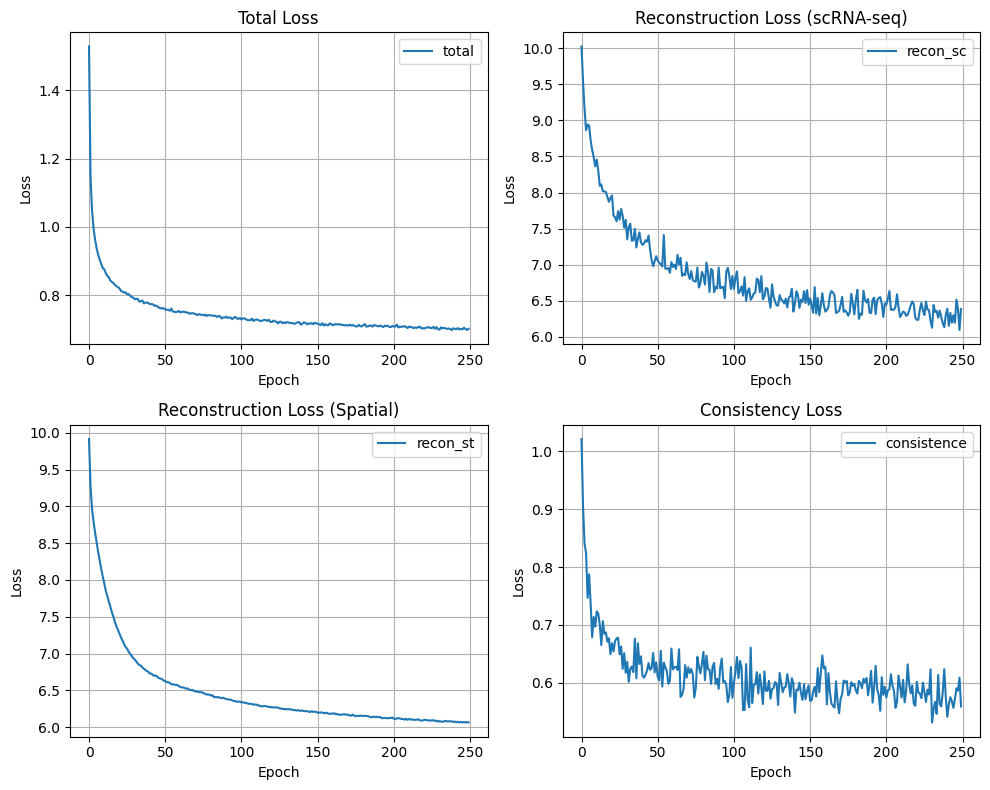

In [ ]:
# Set up titles and axis labels
titles = {
    "total": "Total Loss",
    "recon_sc": "Reconstruction Loss (scRNA-seq)",
    "recon_st": "Reconstruction Loss (Spatial)",
    "consistence": "Consistency Loss"
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, key in enumerate(["total", "recon_sc", "recon_st", "consistence"]):
    value = loss_log.get(key, None)
    if value is not None:
        axes[i].plot(value, label=key)
        axes[i].set_title(titles[key])
        axes[i].set_xlabel("Epoch")
        axes[i].set_ylabel("Loss")
        axes[i].grid(True)
        axes[i].legend()

plt.tight_layout()
plt.show()

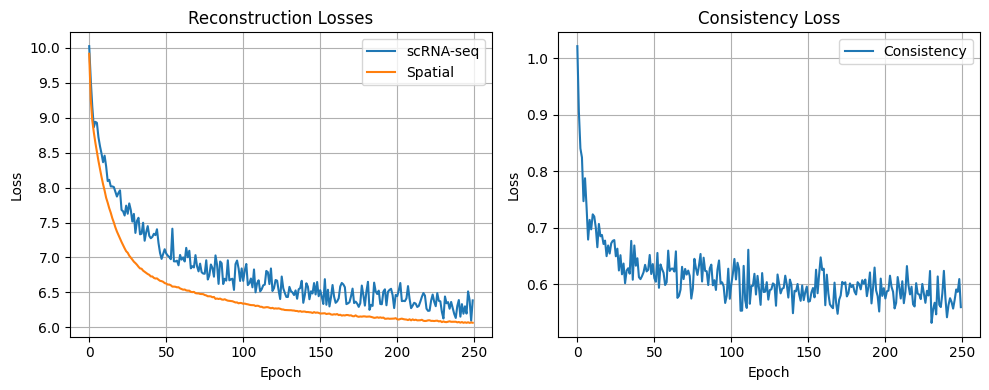

In [ ]:
# Set up titles and axis labels
titles = {
    "recon": "Reconstruction Losses",
    "consistence": "Consistency Loss"
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # 1 row, 2 columns
axes = axes.flatten()

# Panel 1: both reconstruction losses
recon_sc = loss_log.get("recon_sc", None)
recon_st = loss_log.get("recon_st", None)
if recon_sc is not None and recon_st is not None:
    axes[0].plot(recon_sc, label="scRNA-seq")
    axes[0].plot(recon_st, label="Spatial")
    axes[0].set_title(titles["recon"])
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True)
    axes[0].legend()

# Panel 2: consistency loss
consistence = loss_log.get("consistence", None)
if consistence is not None:
    axes[1].plot(consistence, label="Consistency")
    axes[1].set_title(titles["consistence"])
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].grid(True)
    axes[1].legend()

plt.tight_layout()
plt.savefig("/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/AEs_loss_plot.png", dpi=300, bbox_inches='tight')
plt.show()


The final losses show comparabe strength of the two autoencoders, which basically follow the same trajectory.

Consistency loss also stabilizes towards an acceptable value. Ideally, based on the definition, it should approach zero. In this case, we can stop once the loss starts to flatten, given that this is just an initialization phase.

It is worth noticing that the spatial reconstruction term is much smoother than the other signals.

# Save models

In [ ]:
model_path = '/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/'

# Encoders
torch.save(model.ST_encoder.state_dict(), model_path + 'spatial_encoder_weights.pth')
torch.save(model.SC_encoder.state_dict(), model_path + 'scrna_encoder_weights.pth')

# Decoders
torch.save(model.ST_decoder.state_dict(), model_path + 'spatial_decoder_weights.pth')
torch.save(model.SC_decoder.state_dict(), model_path + 'scrna_decoder_weights.pth')